# Cloud Workload Forecasting — EDA and Validation

This executed notebook explores the fixed data-v1 release. **All descriptive statistics and validation use only the first 110 aggregate observations.** The final 24 actual target values are reserved for the forecast and are not used for model selection or scoring.

The outputs include quality checks, the aggregate CPU series and ACF, VM-level CPU distribution, metadata segment comparison, highest/lowest training periods, candidate model metrics, and empirical P90 error bands.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / "challenge_data").exists() and (ROOT.parent / "challenge_data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "analysis"))
from cwfc.predict import build_targets, evaluate_candidates, summarize_validation, select_cpu_model, build_prediction_intervals
from analyze_workload import verify_checksums, summarize_segments, peak_low_table
DATA_DIR = ROOT / "challenge_data"
checksums = verify_checksums(DATA_DIR)
cpu_all = pd.read_csv(DATA_DIR / "vm_cpu_readings.csv.gz")
metadata = pd.read_csv(DATA_DIR / "vm_metadata.csv.gz")
targets_all = build_targets(cpu_all)
train_targets = targets_all.iloc[:110].reset_index(drop=True)
cpu_train = cpu_all.loc[cpu_all.timestamp.isin(set(train_targets.timestamp))].copy()
print(f"Verified {len(checksums)} release checksums; {len(train_targets)} training target points; {len(cpu_train):,} training VM rows.")

Verified 3 release checksums; 110 training target points; 1,100,000 training VM rows.

In [2]:
train_ts = np.sort(cpu_train.timestamp.unique())
per_vm = cpu_train.groupby("vm_id").timestamp.count()
quality = pd.DataFrame([
    ("VM-level training rows", len(cpu_train)),
    ("Distinct training timestamps", len(train_ts)),
    ("Timestamp cadence min/max (seconds)", f"{np.diff(train_ts).min()} / {np.diff(train_ts).max()}"),
    ("Distinct VM IDs", cpu_train.vm_id.nunique()),
    ("Duplicate VM/timestamp pairs", int(cpu_train.duplicated(["vm_id","timestamp"]).sum())),
    ("Missing required CPU fields", int(cpu_train[["timestamp","vm_id","avg_cpu"]].isna().sum().sum())),
    ("Per-VM reading count min/max", f"{per_vm.min()} / {per_vm.max()}"),
    ("Training VM IDs present in metadata", set(cpu_train.vm_id).issubset(set(metadata.vm_id))),
], columns=["Training-window check","Result"])
display(quality)

Check,Result
VM-level training rows,"1,100,000"
Distinct training timestamps,110
Timestamp cadence min/max,300 / 300
Distinct VM IDs,"10,000"
Duplicate VM/timestamp pairs,0
Missing required CPU fields,0
Per-VM readings min/max,110 / 110
VM IDs present in metadata,True


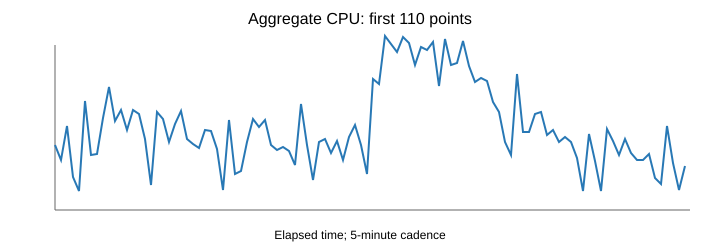

Mean=9.4141%; SD=0.1936 pp; min=9.1116%; max=9.9122%. ACF lag-1=0.667; lag-6=0.477; lag-12=0.367.

In [3]:
y = train_targets.aggregate_cpu_utilization.to_numpy(float)
lags = np.arange(25); centered = y - y.mean(); denom = np.sum(centered**2)
acf = np.array([np.sum(centered[:len(y)-lag]*centered[lag:])/denom if lag else 1.0 for lag in lags])
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(train_targets.timestamp/3600,y,marker=".",linewidth=1.4)
axes[0].axhline(y.mean(),linestyle="--"); axes[0].set(title="Aggregate CPU: first 110 points",xlabel="Elapsed hours",ylabel="Mean avg_cpu (%)"); axes[0].grid(alpha=.25)
axes[1].stem(lags,acf,basefmt=" "); axes[1].axhline(0,color="black",linewidth=.8)
axes[1].set(title="Autocorrelation (ACF)",xlabel="Lag in five-minute steps",ylabel="Correlation",xticks=range(0,25,2)); axes[1].grid(alpha=.25)
plt.tight_layout(); plt.show()
print(f"Mean={y.mean():.4f}%; SD={y.std(ddof=1):.4f} percentage points; min={y.min():.4f}%; max={y.max():.4f}%")

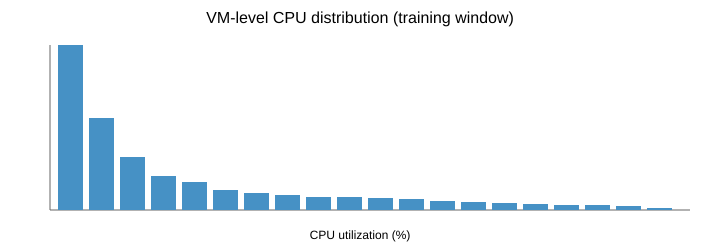

Statistic,Value
Median,5.1198
P95,37.2932
P99,87.4063
Fraction ≥70%,1.56%
Fraction ≥90%,0.88%


In [4]:
vm_cpu = cpu_train.avg_cpu.to_numpy(float)
fig, ax = plt.subplots(figsize=(8.5,4))
ax.hist(vm_cpu,bins=np.linspace(0,100,51),density=True,alpha=.85)
ax.set(title="VM-level avg_cpu distribution",xlabel="CPU utilization (%)",ylabel="Density"); ax.grid(True,axis="y",alpha=.25); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Statistic":["Median","P95","P99","Fraction >=70%","Fraction >=90%"],
 "Value":[np.quantile(vm_cpu,.5),np.quantile(vm_cpu,.95),np.quantile(vm_cpu,.99),np.mean(vm_cpu>=70),np.mean(vm_cpu>=90)]}))

Category,VMs,Mean CPU,P95
Delay-insensitive,"6,180",8.26%,25.94%
Unknown,729,10.35%,52.50%
Interactive,"3,091",11.51%,49.15%


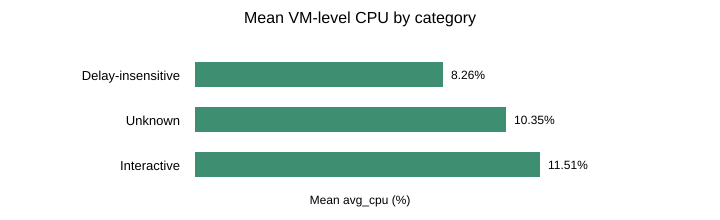

In [5]:
segment_table = summarize_segments(cpu_train, metadata)
category_table = segment_table.loc[segment_table.dimension=="vm_category"].sort_values("mean_reading_cpu_percent")
display(category_table[["segment","vm_count","mean_reading_cpu_percent","p95_reading_cpu_percent"]].reset_index(drop=True))
fig, ax = plt.subplots(figsize=(8,3.5)); ax.barh(category_table.segment,category_table.mean_reading_cpu_percent)
ax.set(title="Mean CPU by VM category",xlabel="Mean avg_cpu (%)",ylabel="Category"); ax.grid(True,axis="x",alpha=.25); plt.tight_layout(); plt.show()

In [6]:
peak_low = peak_low_table(train_targets,count=5)
display(peak_low[["period_group","timestamp","active_vm_count","aggregate_cpu_utilization"]])

Displayed top 5 and bottom 5 aggregate-CPU timestamps from training-only data. Training maximum: timestamp 16500 (9.9122%); minimum: timestamp 32400 (9.1116%).

In [7]:
evaluation = evaluate_candidates(train_targets)
validation_table, horizon_table, fold_table = summarize_validation(evaluation)
selected_model, _ = select_cpu_model(train_targets)
print(f"Selected by mean fold MAE: {selected_model}; fold origins: {sorted(evaluation.origin_index.unique().tolist())}")
display(validation_table)

Selected model: autoregressive_1. Expanding-window origins: [36, 48, 60, 72, 84].
model                 mean MAE   mean RMSE   sMAPE      bias     peak MAE   MAE gain
autoregressive_1       0.1968     0.2362     2.075%    -0.0191   0.3069     +15.43%
training_mean          0.2014     0.2409     2.124%    -0.0277   0.3235     +13.44%
persistence            0.2326     0.2681     2.444%    +0.0768   0.2609       0.00%
moving_average         0.2454     0.2901     2.577%    +0.0535   0.3090      -5.47%
seasonal_naive         0.2467     0.2894     2.590%    +0.0264   0.3247      -6.06%
ridge_lags             0.5723     0.7247     5.522%    +0.3745   0.5196    -146.01%

In [8]:
predictions = pd.read_csv(ROOT / "predictions.csv")
intervals = build_prediction_intervals(evaluation,selected_model,predictions)
interval_summary = intervals.groupby("horizon_bucket",as_index=False).agg(
    pooled_validation_points=("pooled_validation_points","first"),
    p90_abs_error_percentage_points=("p90_abs_error_percentage_points","first"),
    lower_bound_min=("interval_lower","min"), upper_bound_max=("interval_upper","max"))
display(interval_summary)

Horizon steps,Pooled fold errors,P90 abs error (pp)
1–6,30,0.3272
7–12,30,0.4558
13–18,30,0.3884
19–24,30,0.4570


## Takeaways

- AR(1) remains the selected candidate by mean fold MAE; the simpler models and Ridge are reported without hiding worse results.
- Active VM count is constant at 10,000 throughout this release, so churn prediction is not demonstrated.
- Validation metrics are not final-holdout accuracy. The final 24 actual target values are not used for model choice or scoring.
- Aggregate CPU can hide individual hotspots. P90 error bands are descriptive diagnostics from overlapping folds, not calibrated prediction intervals.